In [1]:

# =====================================================================
# ZEROQ AI - OPTIMIZED LOGISTIC REGRESSION
# Sparse data | Regularization | Class weights | Threshold optimization
# =====================================================================

from pathlib import Path
import time
import warnings
import numpy as np
import pandas as pd
import joblib

from scipy.sparse import load_npz

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report,
    log_loss
)

warnings.filterwarnings("ignore")

# =====================================================================
# 1. CONFIGURATION
# =====================================================================

PROJECT_DIR = Path(
    r"D:\AI WORKSHOP\Hackathon\Sakthi Hackathon - ML Training"
)

DATA_DIR = PROJECT_DIR / "model_ready_data"

OUTPUT_DIR = (
    PROJECT_DIR / "model_training" / "logistic_regression_optimized"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

print("=" * 75)
print("ZEROQ AI - OPTIMIZED LOGISTIC REGRESSION")
print("=" * 75)


# =====================================================================
# 2. LOAD DATA
# =====================================================================

print("\nLoading datasets...")

X_train = load_npz(DATA_DIR / "X_train.npz").tocsr()
X_val = load_npz(DATA_DIR / "X_validation.npz").tocsr()
X_test = load_npz(DATA_DIR / "X_test.npz").tocsr()

y_train = np.load(DATA_DIR / "y_train.npy")
y_val = np.load(DATA_DIR / "y_validation.npy")
y_test = np.load(DATA_DIR / "y_test.npy")

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Testing shape:", X_test.shape)

print("\nClass distribution:")

for name, y in [
    ("Training", y_train),
    ("Validation", y_val),
    ("Testing", y_test)
]:
    print(
        f"{name}: "
        f"No Complaint = {np.sum(y == 0)}, "
        f"Complaint = {np.sum(y == 1)}, "
        f"Complaint % = {np.mean(y) * 100:.2f}%"
    )


# =====================================================================
# 3. FEATURE SCALING
# =====================================================================

print("\nScaling sparse features...")

scaler = StandardScaler(with_mean=False)

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")


# =====================================================================
# 4. HYPERPARAMETER SEARCH
# =====================================================================

# Regularization:
# Smaller C = stronger regularization.
# Larger C = weaker regularization.

C_VALUES = [0.001, 0.01, 0.1, 1.0, 10.0]

# Class weights:
# {0: 1, 1: 1} means no class preference.
# Higher positive weights increase the penalty for missing complaints.

CLASS_WEIGHTS = [
    {0: 1.0, 1: 1.0},
    {0: 1.0, 1: 1.25},
    {0: 1.0, 1: 1.5},
    {0: 1.0, 1: 2.0},
    {0: 1.0, 1: 2.5},
    {0: 1.0, 1: 3.0}
]

results = []
trained_models = {}

experiment_number = 0

total_experiments = len(C_VALUES) * len(CLASS_WEIGHTS)

for C in C_VALUES:

    for weight in CLASS_WEIGHTS:

        experiment_number += 1

        print("\n" + "-" * 75)
        print(
            f"Experiment {experiment_number}/{total_experiments}"
        )
        print("Regularization C:", C)
        print("Class weight:", weight)

        model = LogisticRegression(
            penalty="l2",
            C=C,
            solver="saga",
            max_iter=10000,
            tol=0.001,
            class_weight=weight,
            random_state=RANDOM_STATE,
            n_jobs=-1
        )

        start_time = time.time()

        model.fit(X_train_scaled, y_train)

        training_time = time.time() - start_time

        # Validation probabilities
        val_prob = model.predict_proba(X_val_scaled)[:, 1]

        # Evaluate multiple thresholds
        thresholds = np.arange(0.05, 0.951, 0.005)

        threshold_results = []

        for threshold in thresholds:

            val_pred = (val_prob >= threshold).astype(int)

            accuracy = accuracy_score(y_val, val_pred)

            precision = precision_score(
                y_val, val_pred, zero_division=0
            )

            recall = recall_score(
                y_val, val_pred, zero_division=0
            )

            f1 = f1_score(
                y_val, val_pred, zero_division=0
            )

            balanced_acc = balanced_accuracy_score(
                y_val, val_pred
            )

            threshold_results.append({
                "threshold": threshold,
                "accuracy": accuracy,
                "precision": precision,
                "recall": recall,
                "f1": f1,
                "balanced_accuracy": balanced_acc
            })

        threshold_df = pd.DataFrame(threshold_results)

        # Select threshold using validation accuracy.
        # F1 is used as a tie-breaker.
        best_threshold_row = threshold_df.sort_values(
            ["accuracy", "f1"],
            ascending=[False, False]
        ).iloc[0]

        best_threshold = float(
            best_threshold_row["threshold"]
        )

        # Validation discrimination metrics
        val_roc_auc = roc_auc_score(y_val, val_prob)

        val_pr_auc = average_precision_score(
            y_val, val_prob
        )

        # Save experiment
        results.append({
            "C": C,
            "class_weight_positive": weight[1],
            "threshold": best_threshold,
            "validation_accuracy":
                best_threshold_row["accuracy"],
            "validation_precision":
                best_threshold_row["precision"],
            "validation_recall":
                best_threshold_row["recall"],
            "validation_f1":
                best_threshold_row["f1"],
            "validation_balanced_accuracy":
                best_threshold_row["balanced_accuracy"],
            "validation_roc_auc": val_roc_auc,
            "validation_pr_auc": val_pr_auc,
            "training_time_seconds": training_time,
            "iterations": int(np.max(model.n_iter_)),
            "converged": bool(np.max(model.n_iter_) < 10000)
        })

        trained_models[experiment_number] = {
            "model": model,
            "C": C,
            "weight": weight,
            "threshold": best_threshold,
            "validation_accuracy":
                best_threshold_row["accuracy"],
            "validation_f1":
                best_threshold_row["f1"],
            "validation_roc_auc": val_roc_auc
        }

        print("Training time:", round(training_time, 2), "seconds")
        print("Iterations:", np.max(model.n_iter_))
        print("Converged:", np.max(model.n_iter_) < 10000)
        print("Best threshold:", round(best_threshold, 4))
        print(
            "Validation accuracy:",
            round(best_threshold_row["accuracy"] * 100, 2), "%"
        )
        print("Validation F1:", round(best_threshold_row["f1"], 4))
        print("Validation ROC-AUC:", round(val_roc_auc, 4))
        print("Validation PR-AUC:", round(val_pr_auc, 4))


# =====================================================================
# 5. COMPARE EXPERIMENTS
# =====================================================================

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by=[
        "validation_accuracy",
        "validation_f1",
        "validation_roc_auc"
    ],
    ascending=[False, False, False]
)

print("\n" + "=" * 75)
print("HYPERPARAMETER COMPARISON")
print("=" * 75)

print(results_df.to_string(index=False))

results_df.to_csv(
    OUTPUT_DIR / "hyperparameter_comparison.csv",
    index=False
)


# =====================================================================
# 6. SELECT BEST MODEL
# =====================================================================

best_experiment = int(
    results_df.index[0]
) + 1

best_configuration = trained_models[best_experiment]

best_model = best_configuration["model"]

best_threshold = best_configuration["threshold"]

print("\nSelected configuration:")
print("C:", best_configuration["C"])
print("Class weight:", best_configuration["weight"])
print("Threshold:", best_threshold)
print(
    "Validation accuracy:",
    round(
        best_configuration["validation_accuracy"] * 100, 2
    ),
    "%"
)


# =====================================================================
# 7. FINAL TEST EVALUATION
# =====================================================================

# Test data is used only after selecting the model and threshold.

test_prob = best_model.predict_proba(X_test_scaled)[:, 1]

test_pred = (
    test_prob >= best_threshold
).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test,
    test_pred,
    labels=[0, 1]
).ravel()

test_accuracy = accuracy_score(y_test, test_pred)

test_precision = precision_score(
    y_test, test_pred, zero_division=0
)

test_recall = recall_score(
    y_test, test_pred, zero_division=0
)

test_f1 = f1_score(
    y_test, test_pred, zero_division=0
)

test_roc_auc = roc_auc_score(y_test, test_prob)

test_pr_auc = average_precision_score(
    y_test, test_prob
)

print("\n" + "=" * 75)
print("FINAL TEST RESULTS")
print("=" * 75)

print(f"Accuracy:           {test_accuracy * 100:.2f}%")
print(f"Precision:          {test_precision:.4f}")
print(f"Recall:             {test_recall:.4f}")
print(f"F1 Score:           {test_f1:.4f}")
print(f"ROC-AUC:            {test_roc_auc:.4f}")
print(f"PR-AUC:             {test_pr_auc:.4f}")
print(
    "Balanced Accuracy:",
    round(balanced_accuracy_score(y_test, test_pred), 4)
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_pred))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        test_pred,
        target_names=["No Complaint", "Complaint"],
        zero_division=0
    )
)

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)


# =====================================================================
# 8. COMPARE AGAINST MAJORITY BASELINE
# =====================================================================

majority_baseline = max(
    np.mean(y_test == 0),
    np.mean(y_test == 1)
)

print("\nMajority baseline accuracy:",
      round(majority_baseline * 100, 2), "%")

print("Model accuracy:",
      round(test_accuracy * 100, 2), "%")

print("Accuracy improvement:",
      round(
          (test_accuracy - majority_baseline) * 100, 2
      ),
      "percentage points"
)


# =====================================================================
# 9. SAVE MODEL AND SCALER
# =====================================================================

joblib.dump(
    best_model,
    OUTPUT_DIR / "optimized_logistic_regression.joblib"
)

joblib.dump(
    scaler,
    OUTPUT_DIR / "feature_scaler.joblib"
)

joblib.dump(
    best_threshold,
    OUTPUT_DIR / "optimal_threshold.joblib"
)

np.save(
    OUTPUT_DIR / "test_probabilities.npy",
    test_prob
)

np.save(
    OUTPUT_DIR / "test_predictions.npy",
    test_pred
)

# Save validation predictions too
val_prob = best_model.predict_proba(X_val_scaled)[:, 1]

np.save(
    OUTPUT_DIR / "validation_probabilities.npy",
    val_prob
)


# =====================================================================
# 10. SAVE PREDICTION REPORT
# =====================================================================

prediction_df = pd.DataFrame({
    "actual_complaint": y_test,
    "predicted_probability": test_prob,
    "predicted_complaint": test_pred,
    "prediction_result": [
        "Correct" if actual == predicted else "Incorrect"
        for actual, predicted in zip(y_test, test_pred)
    ]
})

prediction_df.to_csv(
    OUTPUT_DIR / "test_prediction_report.csv",
    index=False
)


# =====================================================================
# 11. SAVE FINAL SUMMARY
# =====================================================================

summary = pd.DataFrame([{
    "Model": "Optimized Logistic Regression",
    "C": best_configuration["C"],
    "Positive_Class_Weight":
        best_configuration["weight"][1],
    "Threshold": best_threshold,
    "Test_Accuracy": test_accuracy,
    "Test_Precision": test_precision,
    "Test_Recall": test_recall,
    "Test_F1": test_f1,
    "Test_ROC_AUC": test_roc_auc,
    "Test_PR_AUC": test_pr_auc,
    "Majority_Baseline": majority_baseline,
    "True_Positive": tp,
    "True_Negative": tn,
    "False_Positive": fp,
    "False_Negative": fn
}])

summary.to_csv(
    OUTPUT_DIR / "final_model_summary.csv",
    index=False
)


# =====================================================================
# 12. COMPLETION
# =====================================================================

print("\n" + "=" * 75)
print("OPTIMIZED LOGISTIC REGRESSION COMPLETED")
print("=" * 75)

print("\nSaved files:")
for file in OUTPUT_DIR.iterdir():
    print(file.name)

print("\nOutput directory:")
print(OUTPUT_DIR)


ZEROQ AI - OPTIMIZED LOGISTIC REGRESSION

Loading datasets...
Training shape: (17776, 10038)
Validation shape: (2488, 10038)
Testing shape: (3571, 10038)

Class distribution:
Training: No Complaint = 14031, Complaint = 3745, Complaint % = 21.07%
Validation: No Complaint = 1947, Complaint = 541, Complaint % = 21.74%
Testing: No Complaint = 2820, Complaint = 751, Complaint % = 21.03%

Scaling sparse features...
Feature scaling completed.

---------------------------------------------------------------------------
Experiment 1/30
Regularization C: 0.001
Class weight: {0: 1.0, 1: 1.0}
Training time: 2.63 seconds
Iterations: 132
Converged: True
Best threshold: 0.255
Validation accuracy: 78.3 %
Validation F1: 0.0037
Validation ROC-AUC: 0.5427
Validation PR-AUC: 0.2494

---------------------------------------------------------------------------
Experiment 2/30
Regularization C: 0.001
Class weight: {0: 1.0, 1: 1.25}
Training time: 2.36 seconds
Iterations: 129
Converged: True
Best threshold: 0.

In [2]:
from pathlib import Path
import pandas as pd

OUTPUT_DIR = Path(
    r"D:\AI WORKSHOP\Hackathon\Sakthi Hackathon - ML Training"
) / "model_training" / "logistic_regression_optimized"

comparison = pd.read_csv(
    OUTPUT_DIR / "hyperparameter_comparison.csv"
)

summary = pd.read_csv(
    OUTPUT_DIR / "final_model_summary.csv"
)

print("\n========== ALL 30 EXPERIMENTS ==========")
print(comparison.to_string(index=False))

print("\n========== FINAL TEST METRICS ==========")
print(summary.to_string(index=False))


========== ALL 30 EXPERIMENTS ==========
     C  class_weight_positive  threshold  validation_accuracy  validation_precision  validation_recall  validation_f1  validation_balanced_accuracy  validation_roc_auc  validation_pr_auc  training_time_seconds  iterations  converged
 0.001                   2.00      0.365             0.782958                   1.0           0.001848       0.003690                      0.500924            0.543010           0.249235               2.128438         124       True
 0.001                   1.50      0.315             0.782958                   1.0           0.001848       0.003690                      0.500924            0.542845           0.249343               1.882491         127       True
 0.001                   2.50      0.400             0.782958                   1.0           0.001848       0.003690                      0.500924            0.542828           0.249095               1.963124         122       True
 0.001                   3


ALL EXPERIMENTS - ACCURACY RESULTS
 Experiment    Dataset      C  Positive_Weight  Threshold  Accuracy_Percentage  Precision  Recall  F1_Score  ROC_AUC  PR_AUC
          1   Training  0.001             2.00      0.365              86.1611     0.6081  0.9653    0.7461   0.9596  0.8545
          1 Validation  0.001             2.00      0.365              78.2958     1.0000  0.0018    0.0037   0.5430  0.2492
          1    Testing  0.001             2.00      0.365              78.7174     0.0000  0.0000    0.0000   0.5257  0.2219
          2   Training  0.001             1.50      0.315              86.1105     0.6091  0.9509    0.7426   0.9582  0.8569
          2 Validation  0.001             1.50      0.315              78.2958     1.0000  0.0018    0.0037   0.5428  0.2493
          2    Testing  0.001             1.50      0.315              78.7174     0.0909  0.0013    0.0026   0.5259  0.2219
          3   Training  0.001             2.50      0.400              85.9642     0.6030

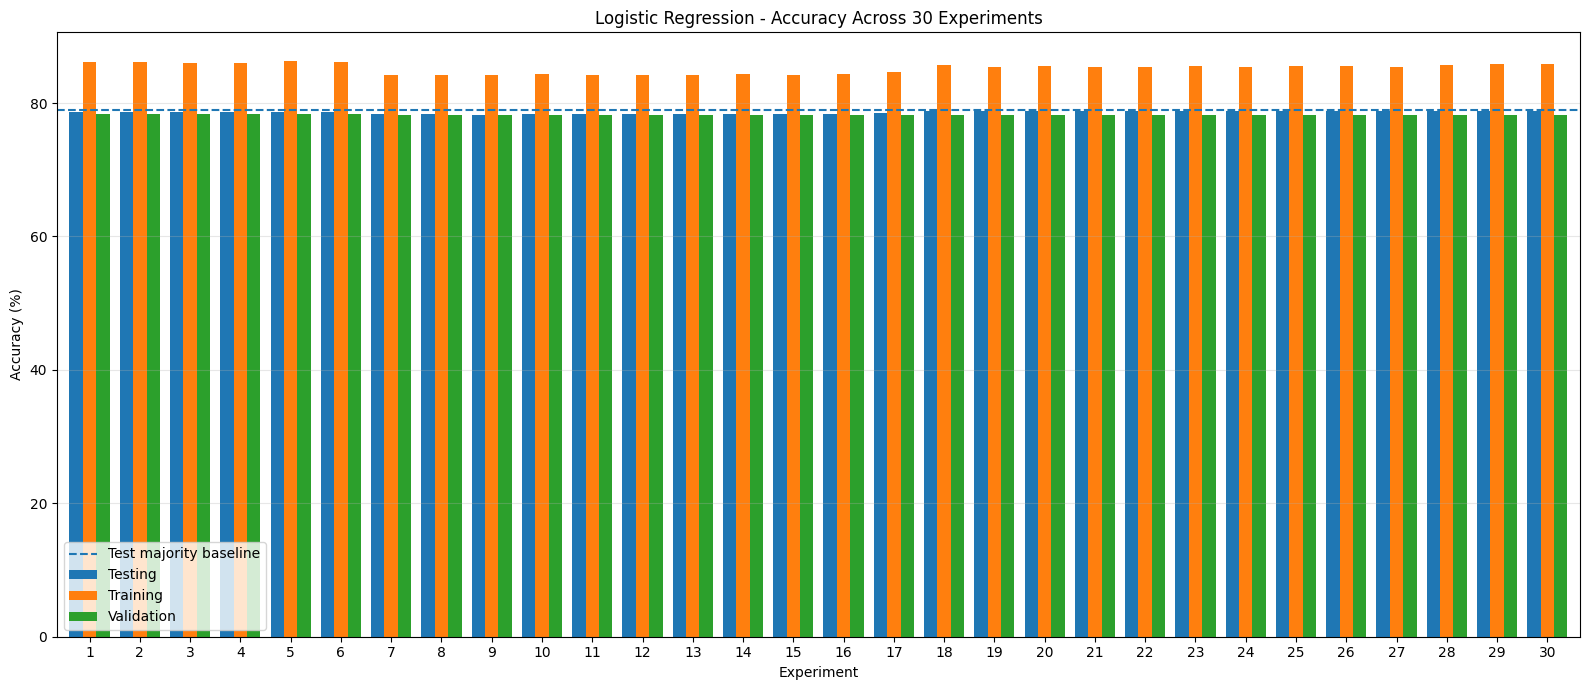


Evaluation completed successfully.
Saved reports:
D:\AI WORKSHOP\Hackathon\Sakthi Hackathon - ML Training\model_training\logistic_regression_optimized\all_experiments_accuracy_results.csv
D:\AI WORKSHOP\Hackathon\Sakthi Hackathon - ML Training\model_training\logistic_regression_optimized\best_experiment_accuracy_report.csv
D:\AI WORKSHOP\Hackathon\Sakthi Hackathon - ML Training\model_training\logistic_regression_optimized\accuracy_comparison_all_experiments.png


In [3]:

# ================================================================
# ZEROQ AI - ACCURACY EVALUATION FOR ALL LOGISTIC REGRESSION MODELS
# ================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# ------------------------------------------------
# 1. PATHS
# ------------------------------------------------

PROJECT_DIR = Path(
    r"D:\AI WORKSHOP\Hackathon\Sakthi Hackathon - ML Training"
)

DATA_DIR = PROJECT_DIR / "model_ready_data"

OUTPUT_DIR = (
    PROJECT_DIR / "model_training" / "logistic_regression_optimized"
)

# ------------------------------------------------
# 2. LOAD LABELS
# ------------------------------------------------

y_train = np.load(DATA_DIR / "y_train.npy")
y_val = np.load(DATA_DIR / "y_validation.npy")
y_test = np.load(DATA_DIR / "y_test.npy")

# ------------------------------------------------
# 3. LOAD EXPERIMENT RESULTS
# ------------------------------------------------

comparison = pd.read_csv(
    OUTPUT_DIR / "hyperparameter_comparison.csv"
)

# ------------------------------------------------
# 4. RECREATE EACH EXPERIMENT'S MODEL
# ------------------------------------------------

from scipy.sparse import load_npz
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

X_train = load_npz(DATA_DIR / "X_train.npz").tocsr()
X_val = load_npz(DATA_DIR / "X_validation.npz").tocsr()
X_test = load_npz(DATA_DIR / "X_test.npz").tocsr()

scaler = StandardScaler(with_mean=False)

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

evaluation_results = []

for index, row in comparison.iterrows():

    C = float(row["C"])
    positive_weight = float(row["class_weight_positive"])
    threshold = float(row["threshold"])

    model = LogisticRegression(
        penalty="l2",
        C=C,
        solver="saga",
        max_iter=10000,
        tol=0.001,
        class_weight={
            0: 1.0,
            1: positive_weight
        },
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_scaled, y_train)

    datasets = [
        ("Training", X_train_scaled, y_train),
        ("Validation", X_val_scaled, y_val),
        ("Testing", X_test_scaled, y_test)
    ]

    for dataset_name, X, y in datasets:

        probabilities = model.predict_proba(X)[:, 1]

        predictions = (
            probabilities >= threshold
        ).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y, predictions, labels=[0, 1]
        ).ravel()

        evaluation_results.append({

            "Experiment": index + 1,
            "Dataset": dataset_name,

            "C": C,
            "Positive_Weight": positive_weight,
            "Threshold": threshold,

            "Accuracy_Percentage":
                accuracy_score(y, predictions) * 100,

            "Precision":
                precision_score(
                    y, predictions, zero_division=0
                ),

            "Recall":
                recall_score(
                    y, predictions, zero_division=0
                ),

            "F1_Score":
                f1_score(
                    y, predictions, zero_division=0
                ),

            "Balanced_Accuracy":
                balanced_accuracy_score(y, predictions),

            "ROC_AUC":
                roc_auc_score(y, probabilities),

            "PR_AUC":
                average_precision_score(y, probabilities),

            "True_Positive": tp,
            "True_Negative": tn,
            "False_Positive": fp,
            "False_Negative": fn
        })

# ------------------------------------------------
# 5. CREATE COMPLETE RESULTS TABLE
# ------------------------------------------------

evaluation_df = pd.DataFrame(evaluation_results)

evaluation_df.to_csv(
    OUTPUT_DIR / "all_experiments_accuracy_results.csv",
    index=False
)

print("\n" + "=" * 90)
print("ALL EXPERIMENTS - ACCURACY RESULTS")
print("=" * 90)

print(
    evaluation_df[
        [
            "Experiment",
            "Dataset",
            "C",
            "Positive_Weight",
            "Threshold",
            "Accuracy_Percentage",
            "Precision",
            "Recall",
            "F1_Score",
            "ROC_AUC",
            "PR_AUC"
        ]
    ].round(4).to_string(index=False)
)

# ------------------------------------------------
# 6. BEST EXPERIMENT BY VALIDATION ACCURACY
# ------------------------------------------------

validation_results = evaluation_df[
    evaluation_df["Dataset"] == "Validation"
].copy()

best_experiment = validation_results.sort_values(
    ["Accuracy_Percentage", "F1_Score"],
    ascending=[False, False]
).iloc[0]

best_id = int(best_experiment["Experiment"])

print("\n" + "=" * 90)
print("BEST EXPERIMENT - VALIDATION")
print("=" * 90)

print(best_experiment.to_string())

# ------------------------------------------------
# 7. DISPLAY BEST MODEL PERFORMANCE
# ------------------------------------------------

best_results = evaluation_df[
    evaluation_df["Experiment"] == best_id
].copy()

print("\n" + "=" * 90)
print("BEST EXPERIMENT - TRAIN / VALIDATION / TEST")
print("=" * 90)

print(
    best_results[
        [
            "Dataset",
            "Accuracy_Percentage",
            "Precision",
            "Recall",
            "F1_Score",
            "Balanced_Accuracy",
            "ROC_AUC",
            "PR_AUC"
        ]
    ].round(4).to_string(index=False)
)

# ------------------------------------------------
# 8. MAJORITY BASELINE
# ------------------------------------------------

baseline = max(
    np.mean(y_test == 0),
    np.mean(y_test == 1)
) * 100

print("\nMajority-class test baseline:",
      round(baseline, 2), "%")

# ------------------------------------------------
# 9. ACCURACY COMPARISON GRAPH
# ------------------------------------------------

plot_data = evaluation_df.pivot(
    index="Experiment",
    columns="Dataset",
    values="Accuracy_Percentage"
)

ax = plot_data.plot(
    kind="bar",
    figsize=(16, 7),
    width=0.8
)

ax.axhline(
    baseline,
    linestyle="--",
    label="Test majority baseline"
)

plt.title("Logistic Regression - Accuracy Across 30 Experiments")
plt.xlabel("Experiment")
plt.ylabel("Accuracy (%)")
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "accuracy_comparison_all_experiments.png",
    dpi=300
)

plt.show()

# ------------------------------------------------
# 10. SAVE BEST EXPERIMENT SUMMARY
# ------------------------------------------------

best_results.to_csv(
    OUTPUT_DIR / "best_experiment_accuracy_report.csv",
    index=False
)

print("\nEvaluation completed successfully.")

print("Saved reports:")
print(OUTPUT_DIR / "all_experiments_accuracy_results.csv")
print(OUTPUT_DIR / "best_experiment_accuracy_report.csv")
print(OUTPUT_DIR / "accuracy_comparison_all_experiments.png")
